# Explainable Machine Learning for Urban Mobility Demand Prediction
## Citi Bike NYC, June 2013: complete, reproducible Google Colab notebook


## 1. Environment and reproducibility

In [ ]:
# Install only what is missing (Colab already ships pandas, scikit-learn, xgboost, matplotlib).
import importlib, subprocess, sys
for pkg, mod in [('xgboost', 'xgboost'), ('shap', 'shap'), ('python-docx', 'docx'), ('pyarrow', 'pyarrow')]:
    try:
        importlib.import_module(mod)
    except ImportError:
        subprocess.check_call([sys.executable, '-m', 'pip', 'install', '-q', pkg])
print('Packages ready.')

Packages ready.


In [ ]:
import os, glob, json, time, shutil, warnings, platform, zipfile
from pathlib import Path
from datetime import datetime

import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
from IPython.display import display

import sklearn, xgboost, shap, joblib
from scipy.stats import spearmanr
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor, plot_tree, export_text
from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import TimeSeriesSplit, GridSearchCV
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.inspection import permutation_importance
from xgboost import XGBRegressor

warnings.filterwarnings('ignore')
RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

try:
    import google.colab  # noqa: F401
    IN_COLAB = True
except ImportError:
    IN_COLAB = False

BASE = Path('/content/citibike_project') if IN_COLAB else Path('citibike_project').resolve()
RAW, CLEAN, RESULTS, FIGS, MODELS = (BASE/'data/raw', BASE/'data/clean', BASE/'results', BASE/'figures', BASE/'models')
for p in [RAW, CLEAN, RESULTS, FIGS, MODELS]:
    p.mkdir(parents=True, exist_ok=True)

# Consistent figure style (matches the thesis figures)
C_BLUE, C_ORANGE, C_GREEN, C_PURPLE = '#2f5f8f', '#c4573a', '#4f8a5b', '#8c6bb1'
MODEL_COLORS = {'Linear Regression': C_BLUE, 'Decision Tree': C_ORANGE, 'Random Forest': C_GREEN, 'XGBoost': C_PURPLE}
plt.rcParams.update({'figure.dpi': 100, 'savefig.dpi': 200, 'axes.grid': True, 'grid.alpha': 0.3,
                     'axes.spines.top': False, 'axes.spines.right': False, 'font.size': 10})

def save_table(df, name):
    df.to_csv(RESULTS/f'{name}.csv', index=False)
    display(df)

def save_fig(name):
    plt.savefig(FIGS/f'{name}.png', bbox_inches='tight')
    plt.show()
    plt.close('all')

print('Python      :', platform.python_version())
print('pandas      :', pd.__version__, '| numpy:', np.__version__)
print('scikit-learn:', sklearn.__version__, '| xgboost:', xgboost.__version__, '| shap:', shap.__version__)
print('Output dir  :', BASE)
print('Run started :', datetime.now().isoformat(timespec='seconds'))

Python      : 3.13.16
pandas      : 2.2.3 | numpy: 2.1.3
scikit-learn: 1.6.1 | xgboost: 3.4.1 | shap: 0.54.1
Output dir  : /content/citibike_project
Run started : 2026-10-24T20:09:31


## 2. Load the June 2013 Citi Bike file

The notebook looks for the file in `/content`, Google Drive (`MyDrive`) and the project folder. If it is not found, an upload button appears.
The file can use either the original 2013 column names (`starttime`, `start station id`, …) or the renamed Kaggle convention (`started_at`, `start_station_id`, …); both are supported.

In [ ]:
FILE_NAME = '201306-citibike-tripdata.csv'

def find_data_file():
    candidates = [os.environ.get('CITIBIKE_CSV', ''), f'/content/{FILE_NAME}', f'/content/drive/MyDrive/{FILE_NAME}',
                  str(RAW/FILE_NAME), FILE_NAME]
    for c in candidates:
        if c and Path(c).is_file():
            return Path(c)
    for root in ['/content', '.']:
        hits = [h for h in glob.glob(f'{root}/**/*201306*.csv', recursive=True) if 'citibike_project/data/clean' not in h]
        if hits:
            return Path(sorted(hits)[0])
    return None

src = find_data_file()
if src is None and IN_COLAB:
    # Optional: uncomment the next two lines to read the file from Google Drive instead of uploading.
    # from google.colab import drive; drive.mount('/content/drive'); src = find_data_file()
    from google.colab import files
    print(f'Please upload {FILE_NAME}')
    up = files.upload()
    src = Path('/content')/next(iter(up))
if src is None:
    raise FileNotFoundError(f'{FILE_NAME} not found. Upload it or set the CITIBIKE_CSV environment variable.')

RAW_FILE = RAW/FILE_NAME
if src.resolve() != RAW_FILE.resolve():
    shutil.copy(src, RAW_FILE)        # raw file preserved unchanged
print('Raw data file:', RAW_FILE, f'({RAW_FILE.stat().st_size/1e6:.1f} MB)')

Please upload 201306-citibike-tripdata.csv


Saving 201306-citibike-tripdata.csv to 201306-citibike-tripdata.csv
Raw data file: /content/citibike_project/data/raw/201306-citibike-tripdata.csv (100.9 MB)


In [ ]:
# Standardise column names to the Kaggle convention used in the thesis (Table 4.2).
RENAME = {'starttime': 'started_at', 'stoptime': 'ended_at',
          'start station id': 'start_station_id', 'start station name': 'start_station_name',
          'start station latitude': 'start_lat', 'start station longitude': 'start_lng',
          'end station id': 'end_station_id', 'end station name': 'end_station_name',
          'end station latitude': 'end_lat', 'end station longitude': 'end_lng',
          'bikeid': 'bike_id', 'usertype': 'member_casual', 'birth year': 'birth_year'}


raw = pd.read_csv(RAW_FILE, low_memory=False)
raw.columns = [c.strip().lower() for c in raw.columns]
raw = raw.rename(columns=RENAME)
if 'bike_id' not in raw.columns and 'bikeid' in raw.columns:
    raw = raw.rename(columns={'bikeid': 'bike_id'})
if 'tripduration' not in raw.columns:   # later releases have no tripduration field
    raw['tripduration'] = (pd.to_datetime(raw['ended_at'], errors='coerce') -
                           pd.to_datetime(raw['started_at'], errors='coerce')).dt.total_seconds()

REQUIRED = ['started_at', 'ended_at', 'start_station_id', 'start_station_name', 'start_lat', 'start_lng',
            'member_casual', 'tripduration', 'bike_id']
missing_cols = [c for c in REQUIRED if c not in raw.columns]
if missing_cols:
    raise ValueError(f'Missing expected columns: {missing_cols}')
print(f'Raw trip records loaded: {len(raw):,}')

# Table 4.2 Missingness in the retained raw fields
table_4_2 = pd.DataFrame({'Variable': REQUIRED,
                          'Missing_n': [int(raw[c].isna().sum()) for c in REQUIRED],
                          'Missing_pct': [round(raw[c].isna().mean()*100, 2) for c in REQUIRED]})
print('Table 4.2 Missingness in the retained raw fields')
save_table(table_4_2, 'table_4_2_missingness')

Raw trip records loaded: 577,703
Table 4.2 Missingness in the retained raw fields


,Variable,Missing_n,Missing_pct
0,started_at,0,0.0
1,ended_at,0,0.0
2,start_station_id,0,0.0
3,start_station_name,0,0.0
4,start_lat,0,0.0
5,start_lng,0,0.0
6,member_casual,0,0.0
7,tripduration,0,0.0
8,bike_id,0,0.0


## 3. Data preparation and cleaning (Table 4.1)

In [ ]:
log = [('Raw trip records loaded', len(raw))]
trips = raw.copy()
trips['started_at'] = pd.to_datetime(trips['started_at'], errors='coerce')
for c in ['start_lat', 'start_lng', 'tripduration']:
    trips[c] = pd.to_numeric(trips[c], errors='coerce')

n = len(trips); trips = trips[trips['started_at'].notna()];            log.append(('Unparseable start timestamp removed', n-len(trips)))
n = len(trips); trips = trips.drop_duplicates();                         log.append(('Exact duplicate records removed', n-len(trips)))
n = len(trips); trips = trips[trips['start_station_id'].notna()];        log.append(('Missing start-station id removed', n-len(trips)))
n = len(trips)
trips = trips[trips['start_lat'].between(40.4, 41.0) & trips['start_lng'].between(-74.3, -73.6)]
log.append(('Implausible coordinates removed', n-len(trips)))

# Durations outside 1 minute - 24 hours are FLAGGED only (not deleted): the target is a departure count.
trips['duration_flag'] = ~trips['tripduration'].between(60, 86400)
log.append(('Implausible trip duration (flagged only)', int(trips['duration_flag'].sum())))
log.append(('Records retained for aggregation', len(trips)))

table_4_1 = pd.DataFrame(log, columns=['Cleaning step', 'Records'])
print('Table 4.1 Data-cleaning log')
save_table(table_4_1, 'table_4_1_cleaning_log')

# End-of-trip fields are excluded from the modelling data (leakage); kept in the clean trip file for audit only.
trips['start_station_id'] = trips['start_station_id'].astype(int)
trips.to_parquet(CLEAN/'clean_trip_level.parquet', index=False)

Table 4.1 Data-cleaning log


,Cleaning step,Records
0,Raw trip records loaded,577703
1,Unparseable start timestamp removed,0
2,Exact duplicate records removed,0
3,Missing start-station id removed,0
4,Implausible coordinates removed,0
5,Implausible trip duration (flagged only),344
6,Records retained for aggregation,577703


## 4. Station-hour dataset (Table 4.3)

In [ ]:
MIN_DEPARTURES = 100
station_counts = trips['start_station_id'].value_counts()
kept_ids = np.sort(station_counts[station_counts >= MIN_DEPARTURES].index.values)
print(f'Stations observed: {station_counts.size} | retained (>= {MIN_DEPARTURES} departures): {kept_ids.size}')

t = trips[trips['start_station_id'].isin(kept_ids)].copy()
t['hour_ts'] = t['started_at'].dt.floor('h')
station_meta = (t.sort_values('started_at').groupby('start_station_id')
                 .agg(station_name=('start_station_name', 'first'), lat=('start_lat', 'median'), lng=('start_lng', 'median')))

# Complete hourly grid between the first and last observed timestamp; empty station-hours coded as zero.
hours = pd.date_range(t['hour_ts'].min(), t['hour_ts'].max(), freq='h')
grid = pd.MultiIndex.from_product([kept_ids, hours], names=['start_station_id', 'hour_ts'])
station_hour = (t.groupby(['start_station_id', 'hour_ts']).size().reindex(grid, fill_value=0)
                  .rename('demand').reset_index())
station_hour = station_hour.join(station_meta, on='start_station_id')
print(f'Station-hour observations: {len(station_hour):,} | zero-demand share: {(station_hour.demand == 0).mean():.1%}')

desc = station_hour['demand'].describe(percentiles=[.25, .5, .75, .9, .95, .99])
table_4_3 = pd.DataFrame({'Statistic': desc.index, 'Hourly demand (rides)': desc.values.round(3)})
print('Table 4.3 Descriptive statistics of station-hour demand')
save_table(table_4_3, 'table_4_3_demand_descriptives')
station_hour.to_parquet(CLEAN/'station_hour_panel.parquet', index=False)

Stations observed: 337 | retained (>= 100 departures): 334
Station-hour observations: 240,814 | zero-demand share: 43.4%
Table 4.3 Descriptive statistics of station-hour demand


,Statistic,Hourly demand (rides)
0,count,240814.000
1,mean,2.398
2,std,3.800
3,min,0.000
4,25%,0.000
5,50%,1.000
6,75%,3.000
7,90%,7.000
8,95%,10.000
9,99%,18.000


## 5. Exploratory data analysis (Figures 4.1–4.8)

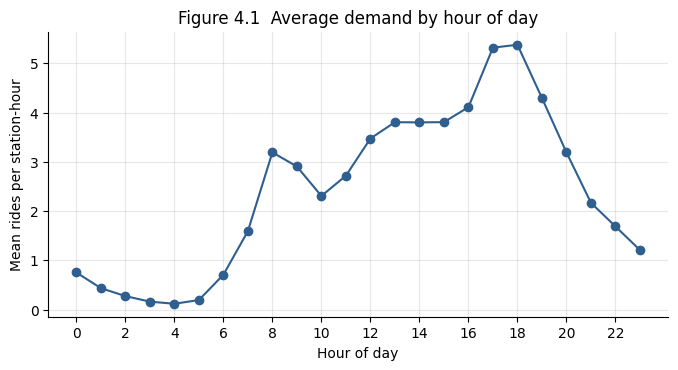

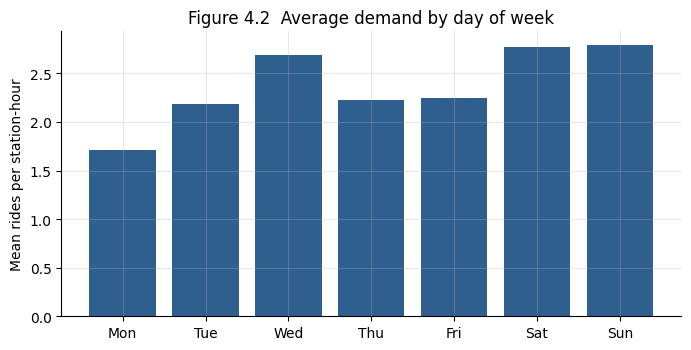

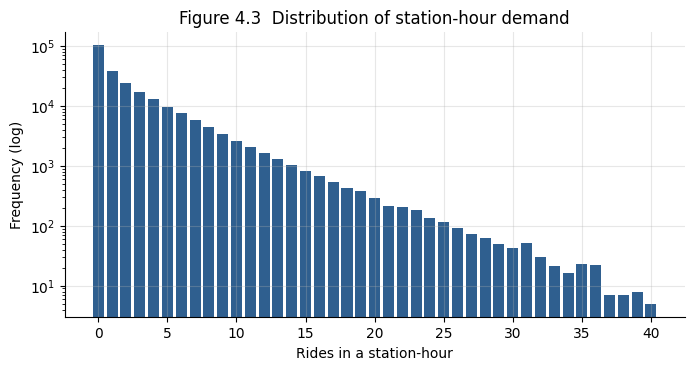

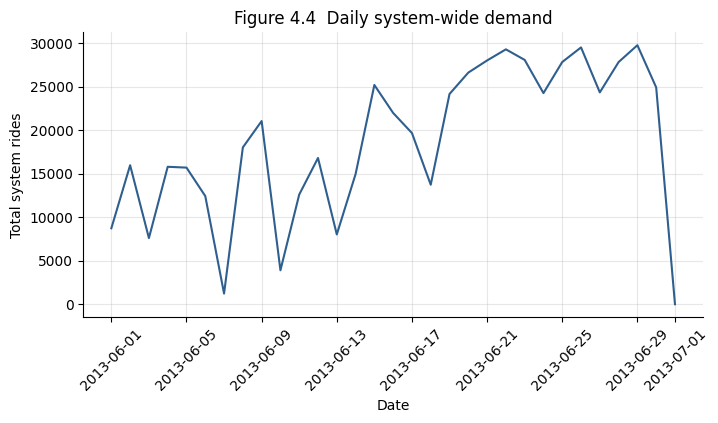

,Station,Total rides
0,W 20 St & 11 Ave,5983
1,E 17 St & Broadway,5621
2,Broadway & W 58 St,5401
3,Broadway & E 14 St,5177
4,Broadway & W 24 St,4955
5,Central Park S & 6 Ave,4925
6,West Thames St,4800
7,West St & Chambers St,4529
8,Lafayette St & E 8 St,4432
9,8 Ave & W 31 St N,4409


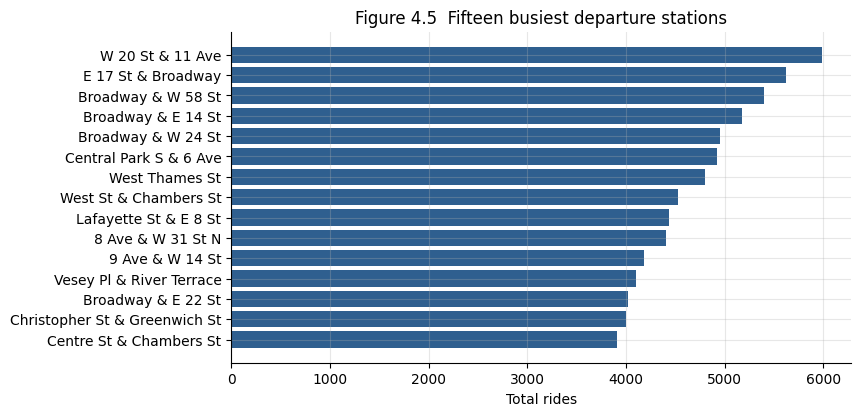

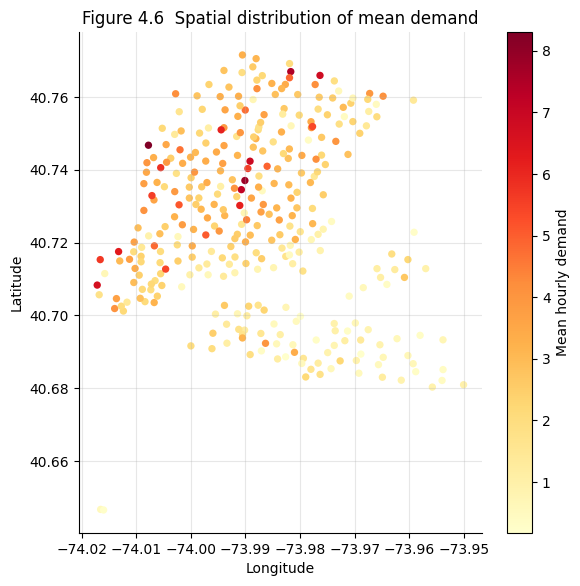

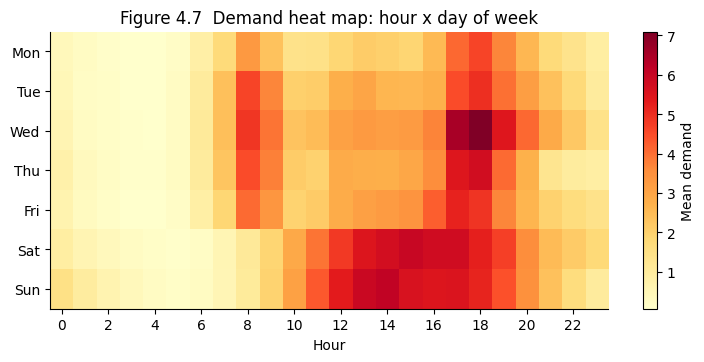

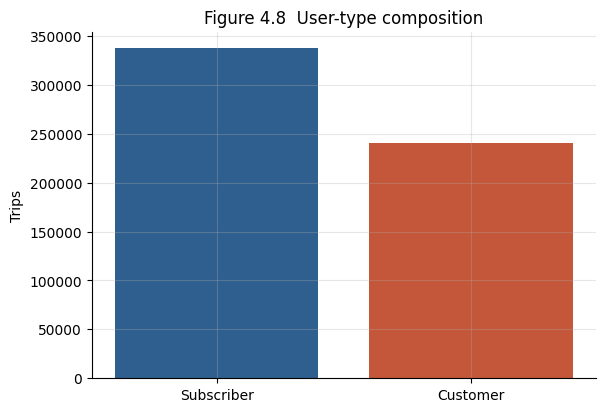

,Trips
member_casual,
Subscriber,337384
Customer,240319


In [ ]:
sh = station_hour.copy()
sh['hour'] = sh['hour_ts'].dt.hour
sh['dow'] = sh['hour_ts'].dt.dayofweek
DAYS = ['Mon', 'Tue', 'Wed', 'Thu', 'Fri', 'Sat', 'Sun']

# Figure 4.1
hourly = sh.groupby('hour')['demand'].mean()
plt.figure(figsize=(8, 3.7))
plt.plot(hourly.index, hourly.values, marker='o', color=C_BLUE)
plt.xticks(range(0, 24, 2)); plt.xlabel('Hour of day'); plt.ylabel('Mean rides per station-hour')
plt.title('Figure 4.1  Average demand by hour of day'); save_fig('figure_4_1_hourly_demand')

# Figure 4.2
dow = sh.groupby('dow')['demand'].mean()
plt.figure(figsize=(8, 3.7))
plt.bar(DAYS, dow.values, color=C_BLUE)
plt.ylabel('Mean rides per station-hour'); plt.title('Figure 4.2  Average demand by day of week')
save_fig('figure_4_2_weekday_demand')

# Figure 4.3
vc = sh['demand'].value_counts().sort_index()
vc = vc[vc.index <= 40]
plt.figure(figsize=(8, 3.7))
plt.bar(vc.index, vc.values, color=C_BLUE); plt.yscale('log')
plt.xlabel('Rides in a station-hour'); plt.ylabel('Frequency (log)')
plt.title('Figure 4.3  Distribution of station-hour demand'); save_fig('figure_4_3_demand_distribution')

# Figure 4.4
daily = sh.groupby(sh['hour_ts'].dt.date)['demand'].sum()
plt.figure(figsize=(8, 3.7))
plt.plot(pd.to_datetime(daily.index), daily.values, color=C_BLUE)
plt.xlabel('Date'); plt.ylabel('Total system rides'); plt.xticks(rotation=45)
plt.title('Figure 4.4  Daily system-wide demand'); save_fig('figure_4_4_daily_demand')

# Figure 4.5
top15 = (sh.groupby('station_name')['demand'].sum().nlargest(15).rename('Total rides').reset_index())
save_table(top15.rename(columns={'station_name': 'Station'}), 'table_top15_stations')
plt.figure(figsize=(8, 4.3))
plt.barh(top15['station_name'][::-1], top15['Total rides'][::-1], color=C_BLUE)
plt.xlabel('Total rides'); plt.title('Figure 4.5  Fifteen busiest departure stations')
save_fig('figure_4_5_top_stations')

# Figure 4.6
st_mean = sh.groupby('start_station_id').agg(lat=('lat', 'first'), lng=('lng', 'first'), mean_demand=('demand', 'mean'))
plt.figure(figsize=(6.5, 6.5))
sc = plt.scatter(st_mean['lng'], st_mean['lat'], c=st_mean['mean_demand'], cmap='YlOrRd', s=28, edgecolors='none')
plt.colorbar(sc, label='Mean hourly demand'); plt.xlabel('Longitude'); plt.ylabel('Latitude')
plt.title('Figure 4.6  Spatial distribution of mean demand'); save_fig('figure_4_6_spatial_demand')

# Figure 4.7
heat = sh.pivot_table(index='dow', columns='hour', values='demand', aggfunc='mean')
plt.figure(figsize=(9, 3.6))
im = plt.imshow(heat.values, aspect='auto', cmap='YlOrRd')
plt.colorbar(im, label='Mean demand'); plt.yticks(range(7), DAYS); plt.xticks(range(0, 24, 2)); plt.xlabel('Hour')
plt.grid(False); plt.title('Figure 4.7  Demand heat map: hour x day of week'); save_fig('figure_4_7_heatmap')

# Figure 4.8 (all recorded trips)
ut = trips['member_casual'].value_counts()
plt.figure(figsize=(6.5, 4.5))
plt.bar(ut.index.astype(str), ut.values, color=[C_BLUE, C_ORANGE][:len(ut)])
plt.ylabel('Trips'); plt.title('Figure 4.8  User-type composition'); save_fig('figure_4_8_user_type')
display(ut.rename('Trips').to_frame())

## 6. Feature engineering (Table 4.4)

In [ ]:
df = station_hour.sort_values(['start_station_id', 'hour_ts']).reset_index(drop=True)
g = df.groupby('start_station_id')['demand']

# Lagged and rolling demand: computed within station and shifted, so y(s,t) never enters its own predictors.
for k in [1, 24, 168]:
    df[f'lag_{k}'] = g.shift(k)
prev = g.shift(1)
for w in [3, 24]:
    df[f'roll_{w}'] = prev.groupby(df['start_station_id']).transform(lambda s: s.rolling(w).mean())

# Calendar and cyclical features
df['hour'] = df['hour_ts'].dt.hour
df['dow'] = df['hour_ts'].dt.dayofweek
df['is_weekend'] = (df['dow'] >= 5).astype(int)
df['hour_sin'] = np.sin(2*np.pi*df['hour']/24); df['hour_cos'] = np.cos(2*np.pi*df['hour']/24)
df['dow_sin'] = np.sin(2*np.pi*df['dow']/7);    df['dow_cos'] = np.cos(2*np.pi*df['dow']/7)
df['am_peak'] = df['hour'].between(7, 9).astype(int)     # 07:00-09:59
df['pm_peak'] = df['hour'].between(16, 19).astype(int)   # 16:00-19:59

# Spatial features (station_hist_mean is added after partitioning, from the training block only)
df['station_code'] = df['start_station_id'].astype('category').cat.codes
FEATURES = ['lag_1', 'lag_24', 'lag_168', 'roll_3', 'roll_24', 'hour', 'dow', 'is_weekend', 'hour_sin', 'hour_cos',
            'dow_sin', 'dow_cos', 'am_peak', 'pm_peak', 'station_code', 'lat', 'lng', 'station_hist_mean']
TARGET = 'demand'

n_before = len(df)
df = df.dropna(subset=['lag_1', 'lag_24', 'lag_168', 'roll_3', 'roll_24']).reset_index(drop=True)
print(f'168-hour warm-up removed {n_before-len(df):,} station-hours; {len(df):,} observations available for modelling.')

table_4_4 = pd.DataFrame([
    ('lag_1', 'Lagged demand', 'Demand in the previous hour at the same station'),
    ('lag_24', 'Lagged demand', 'Demand 24 hours earlier at the same station'),
    ('lag_168', 'Lagged demand', 'Demand 168 hours (one week) earlier at the same station'),
    ('roll_3', 'Lagged demand', 'Mean demand over the previous 3 hours (shifted)'),
    ('roll_24', 'Lagged demand', 'Mean demand over the previous 24 hours (shifted)'),
    ('hour', 'Calendar', 'Hour of day (0-23)'),
    ('dow', 'Calendar', 'Day of week (0 = Monday)'),
    ('is_weekend', 'Calendar (binary)', '1 if Saturday or Sunday'),
    ('hour_sin', 'Cyclical', 'Sine encoding of hour'),
    ('hour_cos', 'Cyclical', 'Cosine encoding of hour'),
    ('dow_sin', 'Cyclical', 'Sine encoding of day of week'),
    ('dow_cos', 'Cyclical', 'Cosine encoding of day of week'),
    ('am_peak', 'Calendar (binary)', '1 if hour is 07:00-09:59'),
    ('pm_peak', 'Calendar (binary)', '1 if hour is 16:00-19:59'),
    ('station_code', 'Spatial', 'Ordinal station identifier'),
    ('lat', 'Spatial', 'Station latitude'),
    ('lng', 'Spatial', 'Station longitude'),
    ('station_hist_mean', 'Spatial', 'Mean demand of the station in the training period only')],
    columns=['Feature', 'Group', 'Definition'])
print('Table 4.4 Data dictionary of engineered predictors')
save_table(table_4_4, 'table_4_4_data_dictionary')

168-hour warm-up removed 56,112 station-hours; 184,702 observations available for modelling.
Table 4.4 Data dictionary of engineered predictors


,Feature,Group,Definition
0,lag_1,Lagged demand,Demand in the previous hour at the same station
1,lag_24,Lagged demand,Demand 24 hours earlier at the same station
2,lag_168,Lagged demand,Demand 168 hours (one week) earlier at the sam...
3,roll_3,Lagged demand,Mean demand over the previous 3 hours (shifted)
4,roll_24,Lagged demand,Mean demand over the previous 24 hours (shifted)
5,hour,Calendar,Hour of day (0-23)
6,dow,Calendar,Day of week (0 = Monday)
7,is_weekend,Calendar (binary),1 if Saturday or Sunday
8,hour_sin,Cyclical,Sine encoding of hour
9,hour_cos,Cyclical,Cosine encoding of hour


## 7. Chronological 70:15:15 partitioning (Table 4.5)

In [ ]:
times = np.sort(df['hour_ts'].unique())
train_end = times[int(len(times)*0.70)]
val_end = times[int(len(times)*0.85)]

# Training-period station mean (no information from validation/test)
hist_mean = df.loc[df['hour_ts'] <= train_end].groupby('start_station_id')['demand'].mean()
df['station_hist_mean'] = df['start_station_id'].map(hist_mean)

df = df.sort_values(['hour_ts', 'start_station_id']).reset_index(drop=True)   # time order for TimeSeriesSplit
train = df[df['hour_ts'] <= train_end].copy()
val = df[(df['hour_ts'] > train_end) & (df['hour_ts'] <= val_end)].copy()
test = df[df['hour_ts'] > val_end].copy()
assert train['hour_ts'].max() < val['hour_ts'].min() and val['hour_ts'].max() < test['hour_ts'].min()

Xtr, ytr = train[FEATURES], train[TARGET]
Xva, yva = val[FEATURES], val[TARGET]
Xte, yte = test[FEATURES], test[TARGET]

table_4_5 = pd.DataFrame({
    'Partition': ['Training', 'Validation', 'Test'],
    'Start': [p['hour_ts'].min() for p in (train, val, test)],
    'End': [p['hour_ts'].max() for p in (train, val, test)],
    'Station-hours': [len(p) for p in (train, val, test)],
    'Share (%)': [round(len(p)/len(df)*100, 1) for p in (train, val, test)],
    'Mean demand': [round(p[TARGET].mean(), 3) for p in (train, val, test)]})
print('Table 4.5 Chronological data partitions')
save_table(table_4_5, 'table_4_5_partitions')
df.to_parquet(CLEAN/'model_ready_station_hour.parquet', index=False)

Table 4.5 Chronological data partitions


,Partition,Start,End,Station-hours,Share (%),Mean demand
0,Training,2013-06-08 00:00:00,2013-06-24 03:00:00,129592,70.2,2.410
1,Validation,2013-06-24 04:00:00,2013-06-27 14:00:00,27722,15.0,3.369
2,Test,2013-06-27 15:00:00,2013-07-01 00:00:00,27388,14.8,3.451


## 8. Hyperparameter selection with time-series cross-validation (Table 4.6)

In [ ]:
tscv = TimeSeriesSplit(n_splits=3)   # expanding window, each fold validated on the following block

def tune(estimator, grid):
    gs = GridSearchCV(estimator, grid, cv=tscv, scoring='neg_mean_absolute_error', n_jobs=1)
    gs.fit(Xtr, ytr)
    res = pd.DataFrame(gs.cv_results_)[['params', 'mean_test_score']].assign(CV_MAE=lambda d: -d.mean_test_score)
    return gs, res.drop(columns='mean_test_score').sort_values('CV_MAE')

t0 = time.time()
dt_gs, dt_cv = tune(DecisionTreeRegressor(random_state=RANDOM_STATE),
                    {'max_depth': [6, 10, 14], 'min_samples_leaf': [20, 50]})
print(f'Decision Tree tuned ({time.time()-t0:.0f}s):', dt_gs.best_params_)

t0 = time.time()
rf_gs, rf_cv = tune(RandomForestRegressor(n_estimators=200, min_samples_leaf=5, max_features=0.6,
                                          random_state=RANDOM_STATE, n_jobs=-1),
                    {'max_depth': [12, 18]})
print(f'Random Forest tuned ({time.time()-t0:.0f}s):', rf_gs.best_params_)

t0 = time.time()
xgb_gs, xgb_cv = tune(XGBRegressor(n_estimators=400, subsample=0.8, colsample_bytree=0.8, objective='reg:squarederror',
                                   tree_method='hist', random_state=RANDOM_STATE, n_jobs=-1),
                      {'learning_rate': [0.05, 0.1], 'max_depth': [6, 8]})
print(f'XGBoost tuned ({time.time()-t0:.0f}s):', xgb_gs.best_params_)

DT_PARAMS = dict(dt_gs.best_params_)
RF_PARAMS = dict(n_estimators=200, min_samples_leaf=5, max_features=0.6, **rf_gs.best_params_)
XGB_PARAMS = dict(n_estimators=400, subsample=0.8, colsample_bytree=0.8, **xgb_gs.best_params_)

table_4_6 = pd.DataFrame([
    ('Linear Regression', 'none (standardised features)', 'intercept + standardisation', '-'),
    ('Decision Tree', 'max_depth {6,10,14} x min_samples_leaf {20,50}', str(DT_PARAMS), round(dt_cv.CV_MAE.iloc[0], 4)),
    ('Random Forest', 'max_depth {12,18}, min_samples_leaf 5, max_features 0.6 (200 trees)', str(RF_PARAMS), round(rf_cv.CV_MAE.iloc[0], 4)),
    ('XGBoost', 'learning_rate {0.05,0.1} x max_depth {6,8}, 400 trees, subsample/colsample 0.8', str(XGB_PARAMS), round(xgb_cv.CV_MAE.iloc[0], 4))],
    columns=['Model', 'Search space', 'Selected configuration', 'CV MAE'])
print('Table 4.6 Hyperparameter search spaces and selected configurations')
save_table(table_4_6, 'table_4_6_hyperparameters')
pd.concat([dt_cv.assign(Model='Decision Tree'), rf_cv.assign(Model='Random Forest'), xgb_cv.assign(Model='XGBoost')]) \
  .to_csv(RESULTS/'tuning_cv_all_configurations.csv', index=False)

Decision Tree tuned (9s): {'max_depth': 10, 'min_samples_leaf': 50}
Random Forest tuned (262s): {'max_depth': 12}
XGBoost tuned (55s): {'learning_rate': 0.05, 'max_depth': 6}
Table 4.6 Hyperparameter search spaces and selected configurations


,Model,Search space,Selected configuration,CV MAE
0,Linear Regression,none (standardised features),intercept + standardisation,-
1,Decision Tree,"max_depth {6,10,14} x min_samples_leaf {20,50}","{'max_depth': 10, 'min_samples_leaf': 50}",1.5526
2,Random Forest,"max_depth {12,18}, min_samples_leaf 5, max_fea...","{'n_estimators': 200, 'min_samples_leaf': 5, '...",1.467
3,XGBoost,"learning_rate {0.05,0.1} x max_depth {6,8}, 40...","{'n_estimators': 400, 'subsample': 0.8, 'colsa...",1.4997


## 9. Final models, validation and test performance (Tables 4.7–4.9, Figure 4.9)
All four models are fitted on the **training block only**, then evaluated on the untouched validation and test blocks. Negative predictions are clipped to zero. Training time is measured on a single CPU core.

Linear Regression  fitted in 0.1s
Decision Tree      fitted in 0.8s
Random Forest      fitted in 76.7s
XGBoost            fitted in 4.4s
Table 4.7 Validation-set performance


,Model,MAE,RMSE,R²
0,Linear Regression,1.7821,2.9252,0.5819
1,Decision Tree,1.7841,2.9500,0.5748
2,Random Forest,1.6613,2.7308,0.6356
3,XGBoost,1.6452,2.7020,0.6433


Table 4.8 Test-set performance


,Model,MAE,RMSE,R²,Training time (s)
0,Linear Regression,1.8562,2.8154,0.6131,0.1
1,Decision Tree,1.8249,2.8572,0.6015,0.8
2,Random Forest,1.7142,2.6537,0.6562,76.7
3,XGBoost,1.7111,2.6754,0.6506,4.4


Table 4.9 Naive seasonal benchmark on the same test observations


,Model,MAE,RMSE,R²
0,Naive (demand 24h earlier),2.4017,3.938,0.243


Lowest test MAE: XGBoost


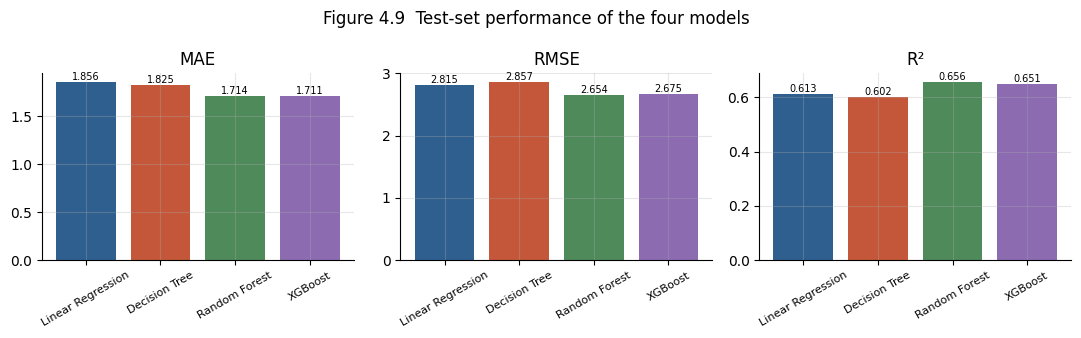

In [ ]:
def metrics(y, p):
    p = np.clip(np.asarray(p, dtype=float), 0, None)
    return {'MAE': round(mean_absolute_error(y, p), 4), 'RMSE': round(mean_squared_error(y, p)**0.5, 4), 'R²': round(r2_score(y, p), 4)}

models = {
    'Linear Regression': Pipeline([('scaler', StandardScaler()), ('model', LinearRegression())]),
    'Decision Tree': DecisionTreeRegressor(random_state=RANDOM_STATE, **DT_PARAMS),
    'Random Forest': RandomForestRegressor(random_state=RANDOM_STATE, n_jobs=1, **RF_PARAMS),
    'XGBoost': XGBRegressor(objective='reg:squarederror', tree_method='hist', random_state=RANDOM_STATE, n_jobs=1, **XGB_PARAMS)}

train_time, pred_val, pred_test = {}, {}, {}
for name, m in models.items():
    t0 = time.time(); m.fit(Xtr, ytr); train_time[name] = round(time.time()-t0, 1)
    pred_val[name] = np.clip(m.predict(Xva), 0, None)
    pred_test[name] = np.clip(m.predict(Xte), 0, None)
    print(f'{name:<18} fitted in {train_time[name]}s')

table_4_7 = pd.DataFrame([{'Model': n, **metrics(yva, p)} for n, p in pred_val.items()])
table_4_8 = pd.DataFrame([{'Model': n, **metrics(yte, p), 'Training time (s)': train_time[n]} for n, p in pred_test.items()])
table_4_9 = pd.DataFrame([{'Model': 'Naive (demand 24h earlier)', **metrics(yte, test['lag_24'])}])
print('Table 4.7 Validation-set performance'); save_table(table_4_7, 'table_4_7_validation_performance')
print('Table 4.8 Test-set performance');      save_table(table_4_8, 'table_4_8_test_performance')
print('Table 4.9 Naive seasonal benchmark on the same test observations'); save_table(table_4_9, 'table_4_9_naive_benchmark')

best_name = table_4_8.sort_values('MAE').iloc[0]['Model']
print('Lowest test MAE:', best_name)

fig, axes = plt.subplots(1, 3, figsize=(11, 3.4))
for ax, met in zip(axes, ['MAE', 'RMSE', 'R²']):
    bars = ax.bar(table_4_8['Model'], table_4_8[met], color=[MODEL_COLORS[m] for m in table_4_8['Model']])
    for b, v in zip(bars, table_4_8[met]):
        ax.text(b.get_x()+b.get_width()/2, b.get_height(), f'{v:.3f}', ha='center', va='bottom', fontsize=7)
    ax.set_title(met); ax.tick_params(axis='x', rotation=30, labelsize=8)
fig.suptitle('Figure 4.9  Test-set performance of the four models'); plt.tight_layout()
save_fig('figure_4_9_test_performance')

## 10. Disaggregated error analysis (Tables 4.10–4.11, Figures 4.10–4.12)

Table 4.10 Test mean absolute error by temporal segment


,Segment,n,Linear Reg.,Dec. Tree,Random Forest,XGBoost
0,Weekday,11356,1.891,1.868,1.747,1.754
1,Weekend,16032,1.832,1.794,1.691,1.681
2,Morning peak (07-09),3006,1.684,1.680,1.492,1.448
3,Evening peak (16-19),5344,2.847,2.904,2.705,2.746
4,Off-peak,19038,1.605,1.545,1.471,1.462
5,Night (00-05),6346,0.759,0.657,0.634,0.640


Table 4.11 Test mean absolute error by observed demand band


,Segment,n,Linear Reg.,Dec. Tree,Random Forest,XGBoost
0,0 rides,8581,1.026,0.834,0.821,0.819
1,1-2,7144,1.502,1.332,1.291,1.256
2,3-5,5483,1.916,1.985,1.886,1.876
3,6-10,4064,2.470,2.756,2.441,2.500
4,>10,2116,5.086,5.303,4.921,4.924


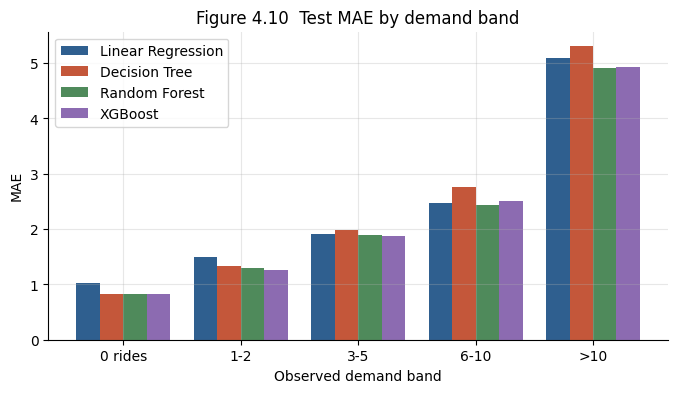

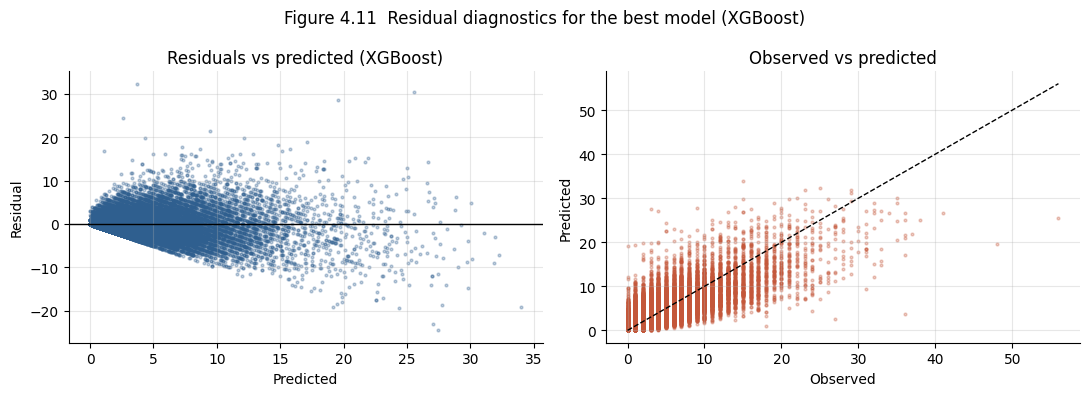

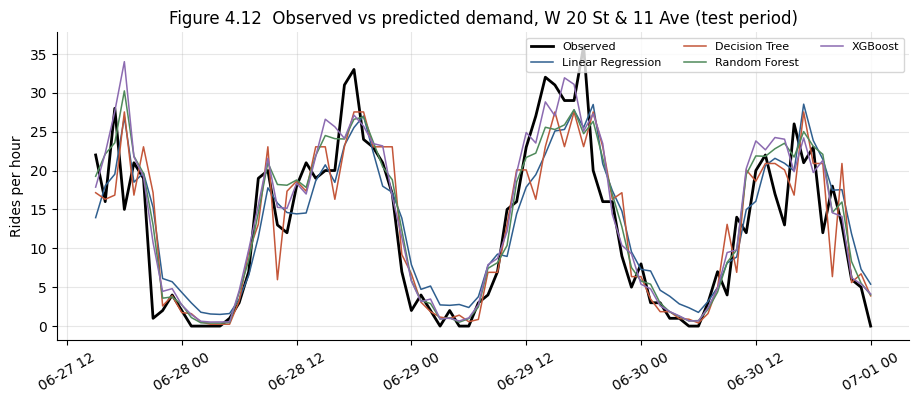

In [ ]:
SHORT = {'Linear Regression': 'Linear Reg.', 'Decision Tree': 'Dec. Tree', 'Random Forest': 'Random Forest', 'XGBoost': 'XGBoost'}
abs_err = {n: np.abs(yte.values - p) for n, p in pred_test.items()}

h = test['hour'].values
segments = {'Weekday': test['is_weekend'].values == 0, 'Weekend': test['is_weekend'].values == 1,
            'Morning peak (07-09)': test['am_peak'].values == 1, 'Evening peak (16-19)': test['pm_peak'].values == 1,
            'Off-peak': (test['am_peak'].values == 0) & (test['pm_peak'].values == 0), 'Night (00-05)': h <= 5}
table_4_10 = pd.DataFrame([{'Segment': s, 'n': int(mask.sum()), **{SHORT[n]: round(e[mask].mean(), 3) for n, e in abs_err.items()}}
                           for s, mask in segments.items()])
print('Table 4.10 Test mean absolute error by temporal segment'); save_table(table_4_10, 'table_4_10_mae_by_segment')

bands = pd.cut(yte, bins=[-1, 0, 2, 5, 10, np.inf], labels=['0 rides', '1-2', '3-5', '6-10', '>10'])
table_4_11 = pd.DataFrame([{'Segment': b, 'n': int((bands == b).sum()), **{SHORT[n]: round(e[(bands == b).values].mean(), 3) for n, e in abs_err.items()}}
                           for b in bands.cat.categories])
print('Table 4.11 Test mean absolute error by observed demand band'); save_table(table_4_11, 'table_4_11_mae_by_demand_band')

# Figure 4.10
x = np.arange(len(table_4_11)); w = 0.2
plt.figure(figsize=(8, 4))
for i, n in enumerate(models):
    plt.bar(x + (i-1.5)*w, table_4_11[SHORT[n]], w, label=n, color=MODEL_COLORS[n])
plt.xticks(x, table_4_11['Segment']); plt.xlabel('Observed demand band'); plt.ylabel('MAE'); plt.legend()
plt.title('Figure 4.10  Test MAE by demand band'); save_fig('figure_4_10_mae_by_band')

# Figure 4.11 Residual diagnostics for the best model
p_best = pred_test[best_name]; resid = yte.values - p_best
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].scatter(p_best, resid, s=4, alpha=0.3, color=C_BLUE); axes[0].axhline(0, color='black', lw=1)
axes[0].set_xlabel('Predicted'); axes[0].set_ylabel('Residual'); axes[0].set_title(f'Residuals vs predicted ({best_name})')
axes[1].scatter(yte, p_best, s=4, alpha=0.3, color=C_ORANGE)
lim = max(yte.max(), p_best.max()); axes[1].plot([0, lim], [0, lim], 'k--', lw=1)
axes[1].set_xlabel('Observed'); axes[1].set_ylabel('Predicted'); axes[1].set_title('Observed vs predicted')
fig.suptitle(f'Figure 4.11  Residual diagnostics for the best model ({best_name})'); plt.tight_layout()
save_fig('figure_4_11_residuals')

# Figure 4.12 Observed vs predicted at the busiest test station
busiest_id = test.groupby('start_station_id')['demand'].sum().idxmax()
busiest_name = station_meta.loc[busiest_id, 'station_name']
mask = (test['start_station_id'] == busiest_id).values
plt.figure(figsize=(11, 4))
plt.plot(test.loc[mask, 'hour_ts'], yte.values[mask], color='black', lw=2, label='Observed')
for n in models:
    plt.plot(test.loc[mask, 'hour_ts'], pred_test[n][mask], lw=1.1, label=n, color=MODEL_COLORS[n])
plt.ylabel('Rides per hour'); plt.legend(ncol=3, fontsize=8); plt.xticks(rotation=30)
plt.title(f'Figure 4.12  Observed vs predicted demand, {busiest_name} (test period)')
save_fig('figure_4_12_busiest_station')

## 11. Explainable ML: linear coefficients and decision-tree rules (Table 4.12, Figures 4.13–4.14)

Table 4.12 Standardised Linear Regression coefficients


,Feature,Standardised coefficient
0,lag_1,1.2267
1,roll_3,0.6688
2,lag_168,0.6407
3,lag_24,0.4672
4,hour_cos,-0.4220
5,station_hist_mean,0.2924
6,pm_peak,0.1899
7,dow_cos,-0.1757
8,am_peak,0.1687
9,hour_sin,-0.1415


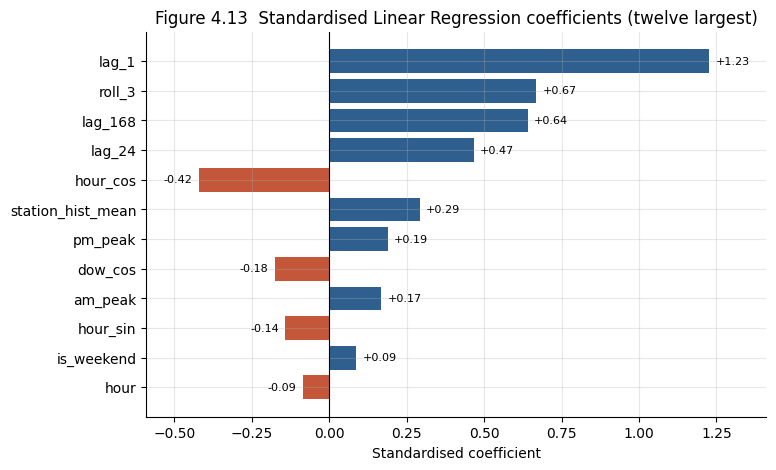

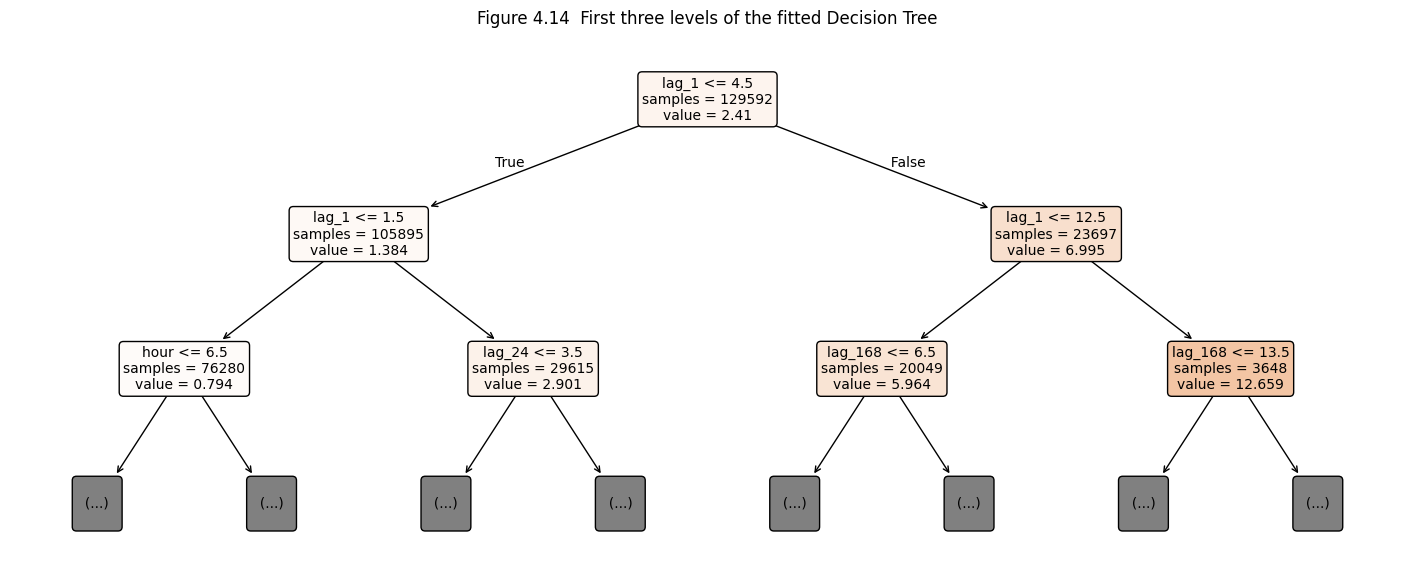

|--- lag_1 <= 4.50
|   |--- lag_1 <= 1.50
|   |   |--- hour <= 6.50
|   |   |   |--- truncated branch of depth 8
|   |   |--- hour >  6.50
|   |   |   |--- truncated branch of depth 8
|   |--- lag_1 >  1.50
|   |   |--- lag_24 <= 3.50
|   |   |   |--- truncated branch of depth 8
|   |   |--- lag_24 >  3.50
|   |   |   |--- truncated branch of depth 8
|--- lag_1 >  4.50
|   |--- lag_1 <= 12.50
|   |   |--- lag_168 <= 6.50
|   |   |   |--- truncated branch of depth 8
|   |   |--- lag_168 >  6.50
|   |   |   |--- truncated branch of depth 8
|   |--- lag_1 >  12.50
|   |   |--- lag_168 <= 13.50
|   |   |   |--- truncated branch of depth 8
|   |   |--- lag_168 >  13.50
|   |   |   |--- truncated branch of depth 6



In [ ]:
lin = models['Linear Regression']
table_4_12 = (pd.DataFrame({'Feature': FEATURES, 'Standardised coefficient': lin.named_steps['model'].coef_.round(4)})
              .sort_values('Standardised coefficient', key=np.abs, ascending=False).reset_index(drop=True))
print('Table 4.12 Standardised Linear Regression coefficients'); save_table(table_4_12, 'table_4_12_linear_coefficients')

top12 = table_4_12.head(12).iloc[::-1]
vals = top12['Standardised coefficient']
plt.figure(figsize=(8, 5))
plt.barh(top12['Feature'], vals, color=[C_BLUE if v > 0 else C_ORANGE for v in vals])
for y_, v in enumerate(vals):
    plt.text(v + (0.02 if v > 0 else -0.02), y_, f'{v:+.2f}', va='center', ha='left' if v > 0 else 'right', fontsize=8)
plt.xlim(min(vals.min()*1.4, 0), vals.max()*1.15)
plt.axvline(0, color='black', lw=0.8); plt.xlabel('Standardised coefficient')
plt.title('Figure 4.13  Standardised Linear Regression coefficients (twelve largest)')
save_fig('figure_4_13_linear_coefficients')

dt_model = models['Decision Tree']
plt.figure(figsize=(18, 7))
plot_tree(dt_model, feature_names=FEATURES, max_depth=2, filled=True, rounded=True, impurity=False, precision=3, fontsize=10)
plt.title('Figure 4.14  First three levels of the fitted Decision Tree'); save_fig('figure_4_14_decision_tree')
(RESULTS/'decision_tree_rules.txt').write_text(export_text(dt_model, feature_names=FEATURES, max_depth=4))
print(export_text(dt_model, feature_names=FEATURES, max_depth=2))

## 12. Permutation importance on the test block (Table 4.13, Figure 4.15)

Linear Regression  done (4s)
Decision Tree      done (1s)
Random Forest      done (55s)
XGBoost            done (26s)
Table 4.13 Permutation importance: increase in MAE when a feature is shuffled


,Feature,Linear Regression,Decision Tree,Random Forest,XGBoost
0,lag_1,0.4545,0.5971,0.3278,0.2708
1,roll_3,0.1668,0.1051,0.1788,0.2577
2,hour_cos,0.0880,0.2145,0.1912,0.2082
3,lag_24,0.1222,0.0655,0.0484,0.1136
4,roll_24,-0.0016,0.0848,0.0628,0.1050
5,lag_168,0.2923,0.0458,0.0702,0.0921
6,station_hist_mean,0.0204,0.0621,0.0588,0.0897
7,hour,0.0038,0.1222,0.0723,0.0876
8,hour_sin,0.0138,0.0214,0.0310,0.0589
9,dow,-0.0003,0.0139,0.0093,0.0283


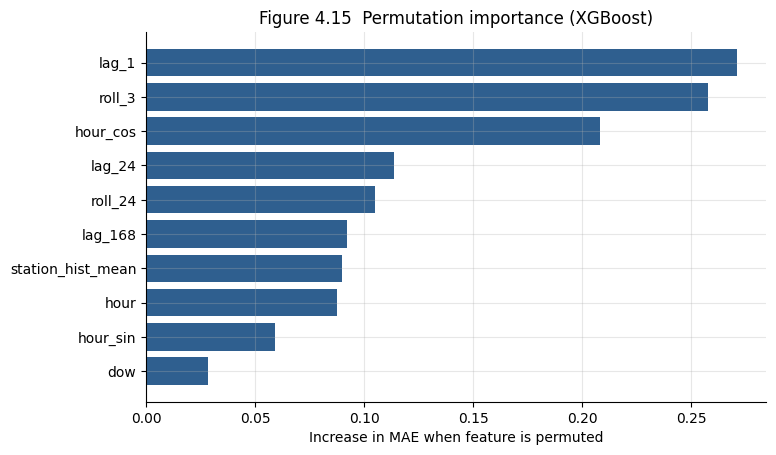

In [ ]:
perm = {}
for name, m in models.items():
    t0 = time.time()
    r = permutation_importance(m, Xte, yte, n_repeats=5, random_state=RANDOM_STATE,
                               scoring='neg_mean_absolute_error', n_jobs=-1)
    perm[name] = pd.Series(r.importances_mean, index=FEATURES)
    print(f'{name:<18} done ({time.time()-t0:.0f}s)')
perm_df = pd.DataFrame(perm)
perm_df.round(4).rename_axis('Feature').reset_index().to_csv(RESULTS/'permutation_importance_all_features.csv', index=False)

table_4_13 = (perm_df.sort_values(best_name, ascending=False).head(15).round(4)
              .rename_axis('Feature').reset_index())
print('Table 4.13 Permutation importance: increase in MAE when a feature is shuffled')
save_table(table_4_13, 'table_4_13_permutation_importance')

topp = perm_df[best_name].sort_values(ascending=False).head(10).iloc[::-1]
plt.figure(figsize=(8, 4.8))
plt.barh(topp.index, topp.values, color=C_BLUE); plt.xlabel('Increase in MAE when feature is permuted')
plt.title(f'Figure 4.15  Permutation importance ({best_name})'); save_fig('figure_4_15_permutation_importance')

## 13. TreeSHAP for the two ensembles (Table 4.14, Figures 4.16–4.19)
SHAP values are calculated on a reproducible random sample of 2,000 test station-hours. The local explanation (Figure 4.19) uses a documented rule: the test station-hour with the largest previous-hour demand at the system peak hour (the hour with the highest mean demand in Figure 4.1).

Random Forest  SHAP done (423s)
XGBoost        SHAP done (4s)
Table 4.14 Mean absolute SHAP values for the two ensemble models


,Feature,Mean |SHAP| Random Forest,Mean |SHAP| XGBoost
0,lag_1,1.1307,1.0347
1,roll_3,0.7294,0.7593
2,hour_cos,0.5456,0.5885
3,lag_168,0.4643,0.3296
4,roll_24,0.2472,0.3195
5,station_hist_mean,0.2516,0.3051
6,lag_24,0.2916,0.2423
7,hour,0.2147,0.2111
8,hour_sin,0.0787,0.1625
9,dow,0.0693,0.1570


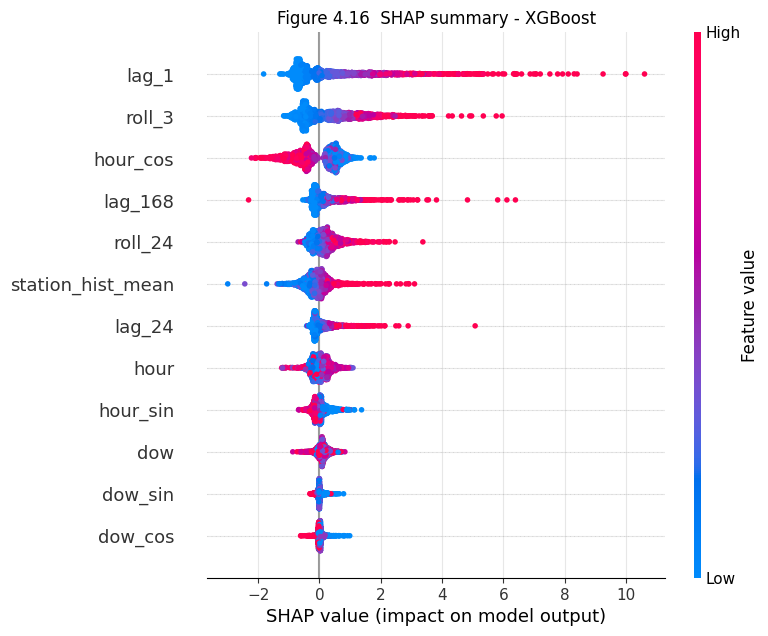

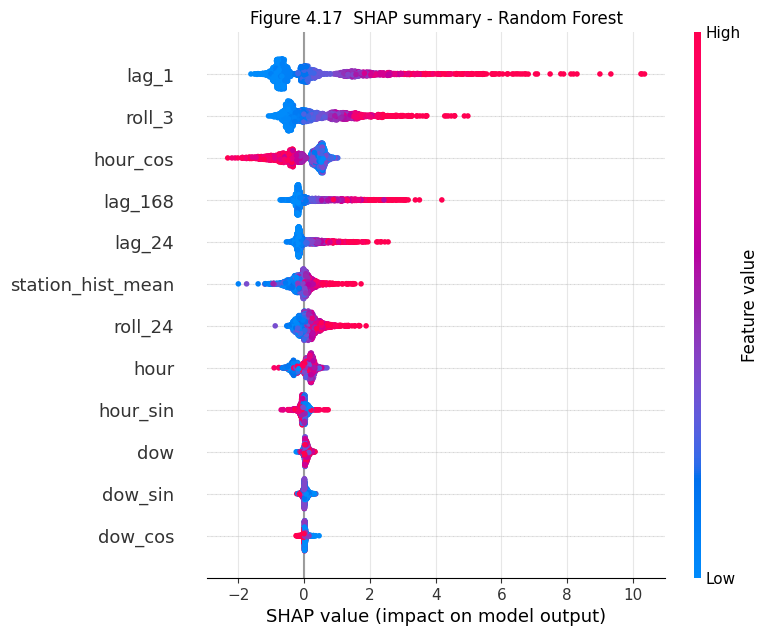

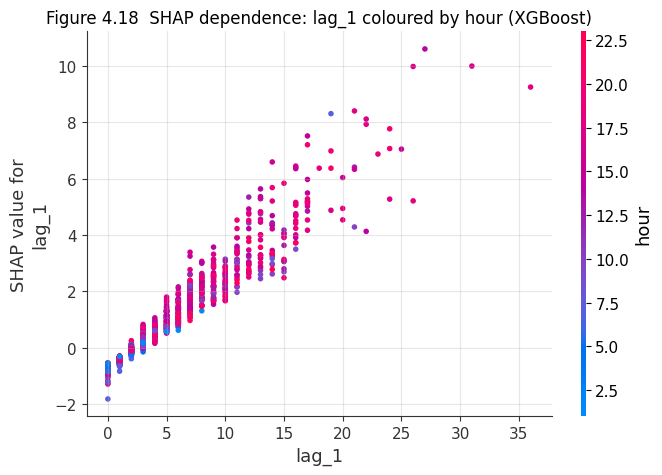

Local case: Broadway & W 24 St, 2013-06-28 18:00:00 | observed = 22, predicted = 25.02, base value = 2.411


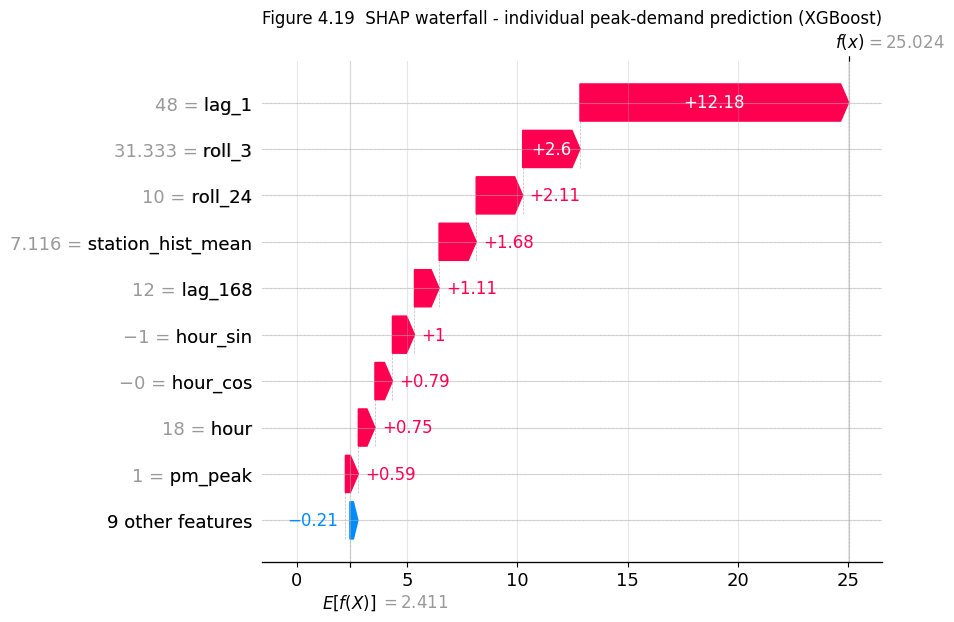

In [ ]:
SHAP_N = 2000
Xshap = Xte.sample(min(SHAP_N, len(Xte)), random_state=RANDOM_STATE)
shap_values, explainers = {}, {}
for name in ['Random Forest', 'XGBoost']:
    t0 = time.time()
    explainers[name] = shap.TreeExplainer(models[name])
    shap_values[name] = explainers[name](Xshap)
    print(f'{name:<14} SHAP done ({time.time()-t0:.0f}s)')

mean_abs = pd.DataFrame({f'Mean |SHAP| {n}': np.abs(shap_values[n].values).mean(axis=0) for n in shap_values}, index=FEATURES)
mean_abs.round(4).rename_axis('Feature').reset_index().to_csv(RESULTS/'mean_abs_shap_all_features.csv', index=False)
table_4_14 = mean_abs.sort_values('Mean |SHAP| XGBoost', ascending=False).head(15).round(4).rename_axis('Feature').reset_index()
print('Table 4.14 Mean absolute SHAP values for the two ensemble models'); save_table(table_4_14, 'table_4_14_mean_abs_shap')

# Figures 4.16 and 4.17 SHAP summary plots
for fig_no, name in [('4_16', 'XGBoost'), ('4_17', 'Random Forest')]:
    shap.summary_plot(shap_values[name].values, Xshap, max_display=12, show=False)
    plt.title(f'Figure {fig_no.replace("_", ".")}  SHAP summary - {name}')
    save_fig(f'figure_{fig_no}_shap_summary_{name.lower().replace(" ", "_")}')

# Figure 4.18 SHAP dependence for lag_1 coloured by hour
shap.dependence_plot('lag_1', shap_values['XGBoost'].values, Xshap, interaction_index='hour', show=False)
plt.title('Figure 4.18  SHAP dependence: lag_1 coloured by hour (XGBoost)')
save_fig('figure_4_18_shap_dependence_lag1')

# Figure 4.19 SHAP waterfall for one peak-demand prediction
peak_hour = int(station_hour.groupby(station_hour['hour_ts'].dt.hour)['demand'].mean().idxmax())
case_idx = test.loc[test['hour'] == peak_hour, 'lag_1'].idxmax()
case = test.loc[[case_idx]]
sv_case = explainers['XGBoost'](case[FEATURES])
print(f"Local case: {case['station_name'].iloc[0]}, {case['hour_ts'].iloc[0]} | observed = {case['demand'].iloc[0]}, "
      f"predicted = {models['XGBoost'].predict(case[FEATURES])[0]:.2f}, base value = {float(np.ravel(sv_case.base_values)[0]):.3f}")
shap.plots.waterfall(sv_case[0], max_display=10, show=False)
plt.title('Figure 4.19  SHAP waterfall - individual peak-demand prediction (XGBoost)')
save_fig('figure_4_19_shap_waterfall')
pd.DataFrame({'Feature': FEATURES, 'Value': case[FEATURES].values[0], 'SHAP': sv_case.values[0]}) \
  .sort_values('SHAP', key=np.abs, ascending=False).to_csv(RESULTS/'shap_local_case.csv', index=False)

## 14. Feature-ranking agreement (Table 4.15)

In [ ]:
# Calculated from the reported (rounded) values in Tables 4.13 and 4.14.
# Spearman = Pearson correlation of descending ranks (average ranks for ties); Jaccard on top-5 sets.
perm_rep = table_4_13.set_index('Feature')[['Random Forest', 'XGBoost']]
shap_rep = table_4_14.set_index('Feature').rename(columns=lambda c: c.replace('Mean |SHAP| ', ''))[['Random Forest', 'XGBoost']]

def agreement(label, a, b):
    common = a.index.intersection(b.index)
    a, b = a[common], b[common]
    rho = spearmanr(a, b)[0]
    top_a, top_b = set(a.nlargest(5).index), set(b.nlargest(5).index)
    return {'Comparison': label, 'n': len(common), 'Spearman ρ': round(float(rho), 3),
            'Top 5 overlap': f'{len(top_a & top_b)}/5', 'Jaccard': round(len(top_a & top_b)/len(top_a | top_b), 3)}

table_4_15 = pd.DataFrame([
    agreement('SHAP: Random Forest vs XGBoost', shap_rep['Random Forest'], shap_rep['XGBoost']),
    agreement('Permutation: Random Forest vs XGBoost', perm_rep['Random Forest'], perm_rep['XGBoost']),
    agreement('Random Forest: SHAP vs permutation', shap_rep['Random Forest'], perm_rep['Random Forest']),
    agreement('XGBoost: SHAP vs permutation', shap_rep['XGBoost'], perm_rep['XGBoost'])])
print('Table 4.15 Feature ranking agreement'); save_table(table_4_15, 'table_4_15_ranking_agreement')

Table 4.15 Feature ranking agreement


,Comparison,n,Spearman ρ,Top 5 overlap,Jaccard
0,SHAP: Random Forest vs XGBoost,15,0.982,4/5,0.667
1,Permutation: Random Forest vs XGBoost,15,0.882,3/5,0.429
2,Random Forest: SHAP vs permutation,14,0.925,4/5,0.667
3,XGBoost: SHAP vs permutation,14,0.938,4/5,0.667


## 15. Multi-criteria model comparison (Table 4.17)

In [ ]:
t8 = table_4_8.set_index('Model')
order = ['Linear Regression', 'Decision Tree', 'Random Forest', 'XGBoost']
table_4_17 = pd.DataFrame({
    'Criterion': ['Test MAE', 'Test RMSE', 'Test R²', 'Training time (s)', 'Intrinsic interpretability (described, not measured)',
                  'Explanation tooling', 'Tuning burden', 'Recommended use'],
    **{m: [t8.loc[m, 'MAE'], t8.loc[m, 'RMSE'], t8.loc[m, 'R²'], t8.loc[m, 'Training time (s)'], interp, tool, tune_b, use]
       for m, interp, tool, tune_b, use in zip(order,
           ['High (signed coefficients)', f"Moderate (upper rules readable; full depth-{DT_PARAMS['max_depth']} tree, only three levels shown)",
            'Low (ensemble average)', 'Low (sequential ensemble)'],
           ['Coefficients', 'Tree diagram, permutation', 'Permutation, TreeSHAP', 'Permutation, TreeSHAP'],
           ['Very low (no hyperparameters tuned)', 'Low', 'Moderate', 'High'],
           ['Transparent benchmark / audit', 'Illustration only; caveat: weakest model in every busy demand band',
            'Robust routine forecasting', 'Operational rebalancing where accuracy dominates'])}})
print('Table 4.17 Multi-criteria comparison of the four models'); save_table(table_4_17, 'table_4_17_multi_criteria')

Table 4.17 Multi-criteria comparison of the four models


,Criterion,Linear Regression,Decision Tree,Random Forest,XGBoost
0,Test MAE,1.8562,1.8249,1.7142,1.7111
1,Test RMSE,2.8154,2.8572,2.6537,2.6754
2,Test R²,0.6131,0.6015,0.6562,0.6506
3,Training time (s),0.1,0.8,76.7,4.4
4,"Intrinsic interpretability (described, not mea...",High (signed coefficients),Moderate (upper rules readable; full depth-10 ...,Low (ensemble average),Low (sequential ensemble)
5,Explanation tooling,Coefficients,"Tree diagram, permutation","Permutation, TreeSHAP","Permutation, TreeSHAP"
6,Tuning burden,Very low (no hyperparameters tuned),Low,Moderate,High
7,Recommended use,Transparent benchmark / audit,Illustration only; caveat: weakest model in ev...,Robust routine forecasting,Operational rebalancing where accuracy dominates


## 16. Save models, versions and download all outputs

In [ ]:
for name, m in models.items():
    joblib.dump(m, MODELS/f"{name.lower().replace(' ', '_')}.joblib")

versions = {'python': platform.python_version(), 'pandas': pd.__version__, 'numpy': np.__version__,
            'scikit-learn': sklearn.__version__, 'xgboost': xgboost.__version__, 'shap': shap.__version__,
            'matplotlib': matplotlib.__version__, 'random_state': RANDOM_STATE,
            'train_end': str(pd.Timestamp(train_end)), 'val_end': str(pd.Timestamp(val_end)),
            'DT_PARAMS': DT_PARAMS, 'RF_PARAMS': RF_PARAMS, 'XGB_PARAMS': XGB_PARAMS}
(RESULTS/'run_configuration.json').write_text(json.dumps(versions, indent=2, default=str))

zip_path = BASE.parent/'citibike_results.zip'
with zipfile.ZipFile(zip_path, 'w', zipfile.ZIP_DEFLATED) as z:
    for folder in [RESULTS, FIGS]:
        for f in sorted(folder.glob('*')):
            z.write(f, f.relative_to(BASE))
print(f"Saved {len(list(RESULTS.glob('*')))} result files and {len(list(FIGS.glob('*.png')))} figures -> {zip_path}")
if IN_COLAB:
    from google.colab import files
    files.download(str(zip_path))

Saved 23 result files and 19 figures -> /content/citibike_results.zip


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## 17. (Optional) Word report with all tables and figures

In [ ]:
from docx import Document
from docx.shared import Inches, Pt
from docx.enum.text import WD_ALIGN_PARAGRAPH

def add_df(doc, title, frame):
    doc.add_paragraph(title).runs[0].bold = True
    tbl = doc.add_table(rows=1, cols=len(frame.columns)); tbl.style = 'Table Grid'
    for j, c in enumerate(frame.columns):
        tbl.rows[0].cells[j].text = str(c)
    for _, row in frame.iterrows():
        cells = tbl.add_row().cells
        for j, v in enumerate(row):
            cells[j].text = f'{v:.4f}' if isinstance(v, (float, np.floating)) else str(v)
    doc.add_paragraph()

def add_fig(doc, name, caption):
    path = FIGS/f'{name}.png'
    if path.exists():
        doc.add_picture(str(path), width=Inches(6.0))
        cap = doc.add_paragraph(caption); cap.alignment = WD_ALIGN_PARAGRAPH.CENTER

report = Document()
report.styles['Normal'].font.name = 'Times New Roman'; report.styles['Normal'].font.size = Pt(11)
report.add_heading('Citi Bike June 2013: Explainable ML Results', level=0)
report.add_paragraph(f"Generated {datetime.now():%Y-%m-%d %H:%M}. Unit of analysis: station-hour. "
                     'Models: Linear Regression, Decision Tree, Random Forest and XGBoost.')

tables = [('Table 4.1 Data-cleaning log', table_4_1), ('Table 4.2 Missingness in the retained raw fields', table_4_2),
          ('Table 4.3 Descriptive statistics of station-hour demand', table_4_3), ('Table 4.4 Data dictionary of engineered predictors', table_4_4),
          ('Table 4.5 Chronological data partitions', table_4_5), ('Table 4.6 Hyperparameter search spaces and selected configurations', table_4_6),
          ('Table 4.7 Validation-set performance', table_4_7), ('Table 4.8 Test-set performance', table_4_8),
          ('Table 4.9 Naive seasonal benchmark', table_4_9), ('Table 4.10 Test MAE by temporal segment', table_4_10),
          ('Table 4.11 Test MAE by observed demand band', table_4_11), ('Table 4.12 Standardised Linear Regression coefficients', table_4_12),
          ('Table 4.13 Permutation importance', table_4_13), ('Table 4.14 Mean absolute SHAP values', table_4_14),
          ('Table 4.15 Feature ranking agreement', table_4_15), ('Table 4.17 Multi-criteria comparison', table_4_17)]
figures = sorted(FIGS.glob('figure_4_*.png'), key=lambda p: int(p.stem.split('_')[2]))

report.add_heading('Tables', level=1)
for title, frame in tables:
    add_df(report, title, frame)
report.add_heading('Figures', level=1)
for f in figures:
    add_fig(report, f.stem, f"Figure 4.{f.stem.split('_')[2]}")

out = BASE.parent/'Citi_Bike_Explainable_ML_Results_Report.docx'
report.save(out)
print('Created:', out)
if IN_COLAB:
    from google.colab import files
    files.download(str(out))

Created: /content/Citi_Bike_Explainable_ML_Results_Report.docx


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>